In [54]:
from IPython.display import display
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import pandas as pd
import random
import seaborn as sns
from utilsforecast.plotting import plot_series

# 1

In [2]:
DATA_DIR = '../../../data/'

In [3]:
target_files = (
    'aus_production.csv', 'pelt.csv', 'gafa_stock.csv', 'vic_elec.csv'
)

In [4]:
files_to_dfs = dict()
for file in target_files:
    print("Lendo", file)
    files_to_dfs[file.split('.')[0]] = pd.read_csv(DATA_DIR + file, parse_dates=['ds'])

Lendo aus_production.csv
Lendo pelt.csv
Lendo gafa_stock.csv
Lendo vic_elec.csv


aus_production
<class 'pandas.DataFrame'>
RangeIndex: 218 entries, 0 to 217
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   ds           218 non-null    datetime64[us]
 1   Beer         218 non-null    int64         
 2   Tobacco      194 non-null    float64       
 3   Bricks       198 non-null    float64       
 4   Cement       218 non-null    int64         
 5   Electricity  218 non-null    int64         
 6   Gas          218 non-null    int64         
dtypes: datetime64[us](1), float64(2), int64(4)
memory usage: 12.1 KB
1956-01-01 to 2010-04-01


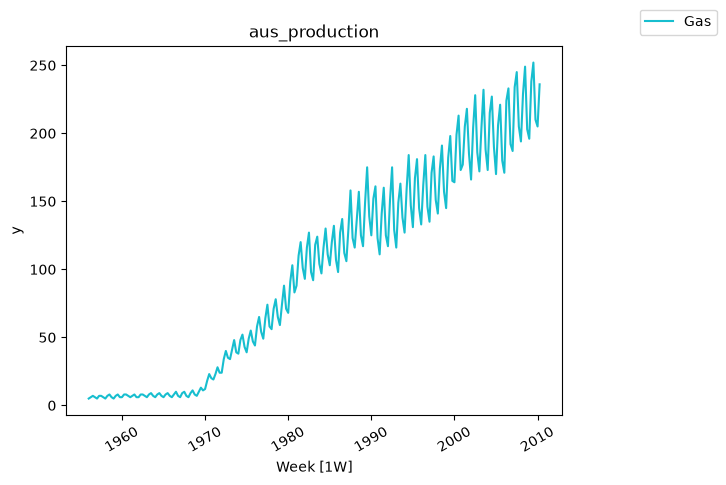


pelt
<class 'pandas.DataFrame'>
RangeIndex: 182 entries, 0 to 181
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   unique_id  182 non-null    str           
 1   ds         182 non-null    datetime64[us]
 2   y          182 non-null    int64         
dtypes: datetime64[us](1), int64(1), str(1)
memory usage: 4.4 KB
1845-01-01 to 1935-01-01


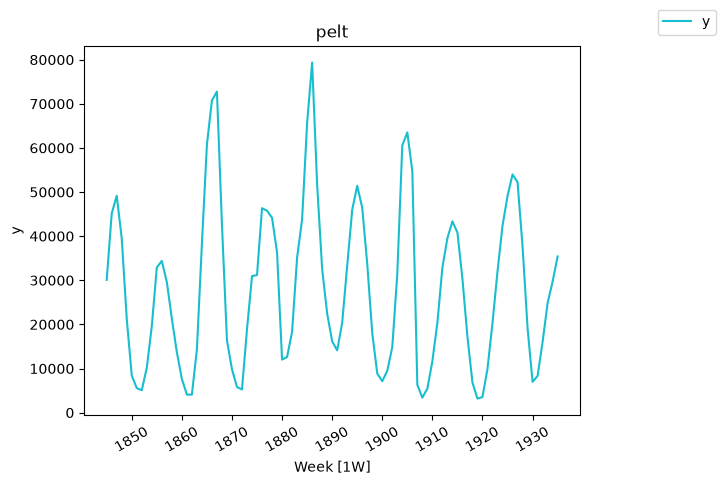


gafa_stock
<class 'pandas.DataFrame'>
RangeIndex: 30192 entries, 0 to 30191
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   unique_id  30192 non-null  str           
 1   ds         30192 non-null  datetime64[us]
 2   y          30192 non-null  float64       
dtypes: datetime64[us](1), float64(1), str(1)
memory usage: 707.8 KB
2014-01-02 to 2018-12-31


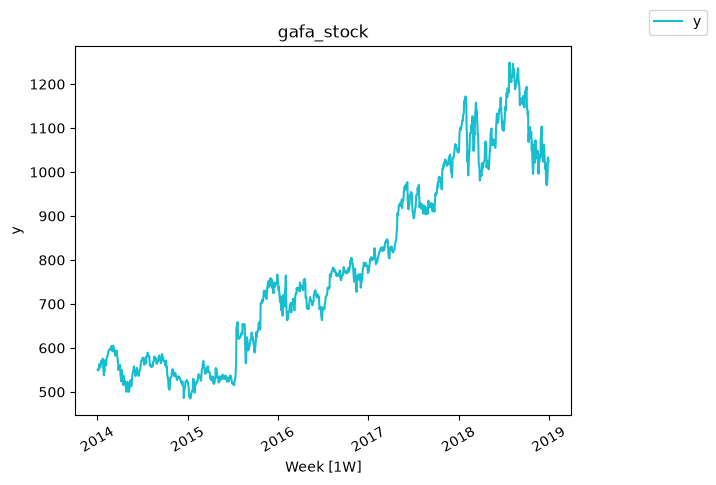


vic_elec
<class 'pandas.DataFrame'>
RangeIndex: 105204 entries, 0 to 105203
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   ds         105204 non-null  datetime64[us]
 1   unique_id  105204 non-null  str           
 2   y          105204 non-null  float64       
 3   Holiday    105204 non-null  bool          
dtypes: bool(1), datetime64[us](1), float64(1), str(1)
memory usage: 2.5 MB
2012-01-01 to 2014-12-31


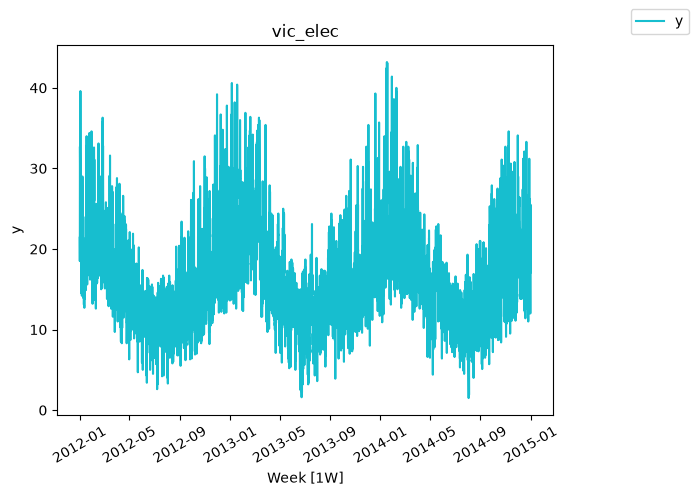

In [5]:
for file_name, df in files_to_dfs.items():
    print(file_name)
    df.info()
    print(df['ds'].min().date(), 'to', df['ds'].max().date())
    if 'unique_id' not in df:
        df['unique_id'] = 1
    fig, ax = plt.subplots()
    fig = plot_series(df=df, time_col='ds', target_col='y' if 'y' in df.columns else 'Gas',
                       ax=ax)
    ax.set(
        xlabel="Week [1W]",
        ylabel='y',
        title=file_name)
    display(fig)
    plt.close()
    print()

# 2

In [6]:
gafa_stock_df = files_to_dfs['gafa_stock']

In [7]:
gafa_stock_df.unique_id.unique()

<StringArray>
[     'AAPL_Open',      'AMZN_Open',        'FB_Open',      'GOOG_Open',
      'AAPL_High',      'AMZN_High',        'FB_High',      'GOOG_High',
       'AAPL_Low',       'AMZN_Low',         'FB_Low',       'GOOG_Low',
     'AAPL_Close',     'AMZN_Close',       'FB_Close',     'GOOG_Close',
 'AAPL_Adj_Close', 'AMZN_Adj_Close',   'FB_Adj_Close', 'GOOG_Adj_Close',
    'AAPL_Volume',    'AMZN_Volume',      'FB_Volume',    'GOOG_Volume']
Length: 24, dtype: str

In [8]:
closing_vals = ('AAPL_Close',     'AMZN_Close',       'FB_Close',     'GOOG_Close')
for val in closing_vals:
    target_val_rows = gafa_stock_df.loc[gafa_stock_df['unique_id'] == val]
    max_y_ds = target_val_rows.loc[target_val_rows['y'] == target_val_rows['y'].max(), 'ds'].item()
    print(val, max_y_ds)

AAPL_Close 2018-10-03 00:00:00
AMZN_Close 2018-09-04 00:00:00
FB_Close 2018-07-25 00:00:00
GOOG_Close 2018-07-26 00:00:00


# 3

In [9]:
tute1 = pd.read_csv(DATA_DIR + "tute1.csv", parse_dates=['Quarter']).rename(columns={"Quarter":"ds"}).assign(unique_id=1)
tute1.head()

,ds,Sales,AdBudget,GDP,unique_id
0,1981-03-01,1020.2,659.2,251.8,1
1,1981-06-01,889.2,589.0,290.9,1
2,1981-09-01,795.0,512.5,290.8,1
3,1981-12-01,1003.9,614.1,292.4,1
4,1982-03-01,1057.7,647.2,279.1,1


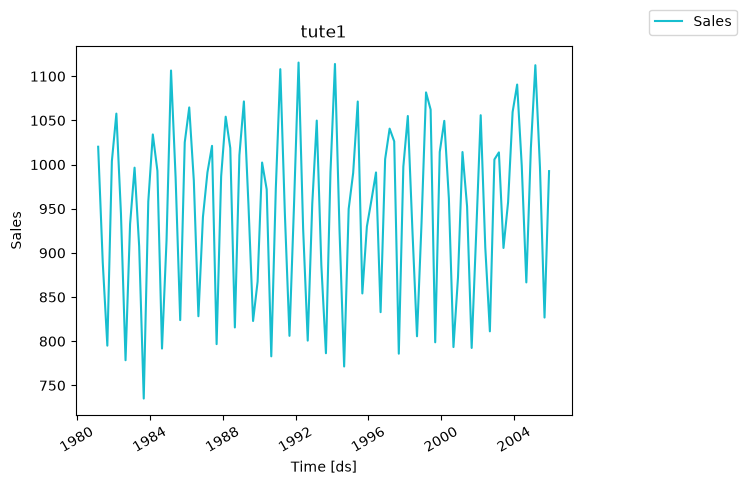

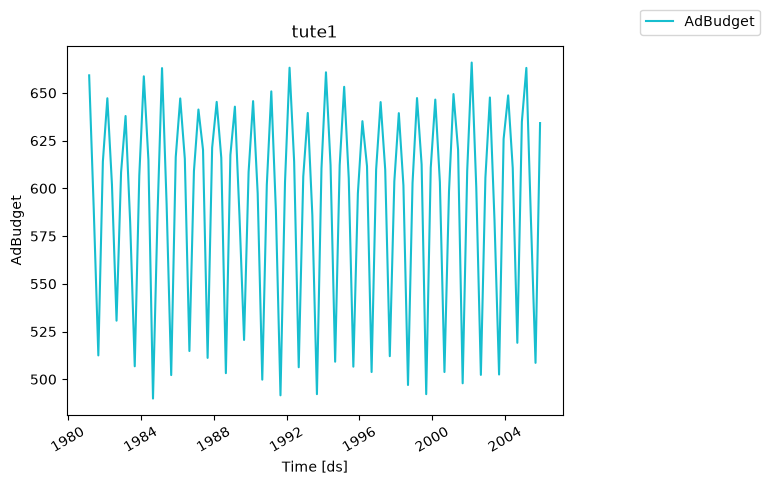

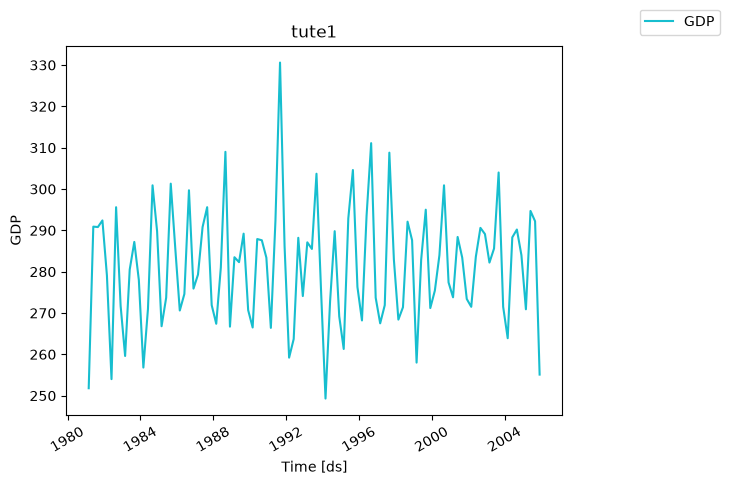

In [10]:
for col in [x for x in tute1.columns if x not in ('ds', 'unique_id')]:
    fig, ax = plt.subplots()
    fig = plot_series(tute1, target_col=col, ax=ax)
    ax.set(title='tute1', ylabel=col)
    display(fig)

# 4

In [11]:
us_gas_demand_df = pd.read_csv(DATA_DIR + "us_total.csv", parse_dates=['ds']).set_index('ds')
us_gas_demand_df.head()

,unique_id,y
ds,,
1997-01-01,Alabama,324158
1998-01-01,Alabama,329134
1999-01-01,Alabama,337270
2000-01-01,Alabama,353614
2001-01-01,Alabama,332693


In [12]:
target_states = ('Maine', 'Vermont', 'New Hampshire', 'Massachusetts', 'Connecticut', 'Rhode Island')
target_data = us_gas_demand_df.loc[us_gas_demand_df['unique_id'].isin(target_states)]

In [13]:
target_data.head()

,unique_id,y
ds,,
1997-01-01,Connecticut,144708
1998-01-01,Connecticut,131497
1999-01-01,Connecticut,152237
2000-01-01,Connecticut,159712
2001-01-01,Connecticut,146278


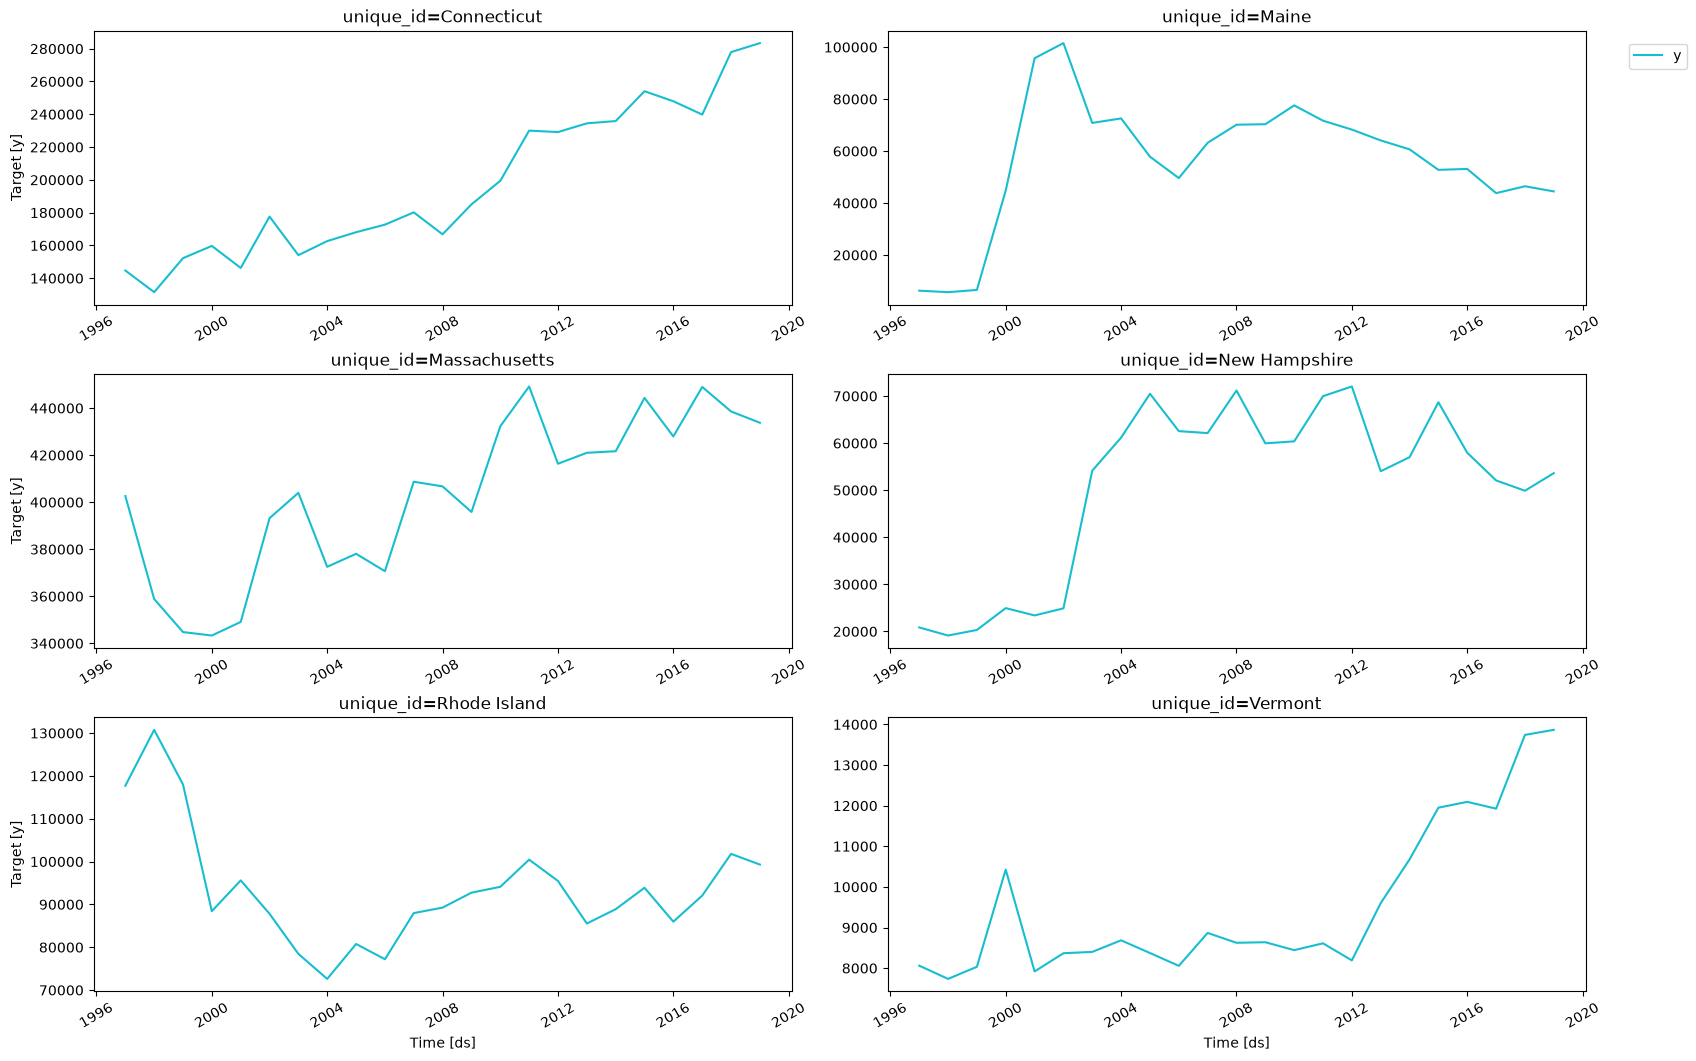

In [14]:
plot_series(target_data.reset_index(drop=False))

# 6

In [43]:
aus_arrivals_df = (
    pd.read_csv(DATA_DIR + "aus_arrivals.csv", parse_dates=['Quarter']).rename(columns={"Quarter":'ds'})
)
aus_arrivals_df = aus_arrivals_df.assign(
    Month=aus_arrivals_df['ds'].dt.month,
    month_name=aus_arrivals_df["ds"].dt.month_name(),
    Year=aus_arrivals_df['ds'].dt.year,
)
aus_arrivals_df.head()

,ds,Origin,Arrivals,Month,month_name,Year
0,1981-01-01,Japan,14763,1,January,1981
1,1981-04-01,Japan,9321,4,April,1981
2,1981-07-01,Japan,10166,7,July,1981
3,1981-10-01,Japan,19509,10,October,1981
4,1982-01-01,Japan,17117,1,January,1982


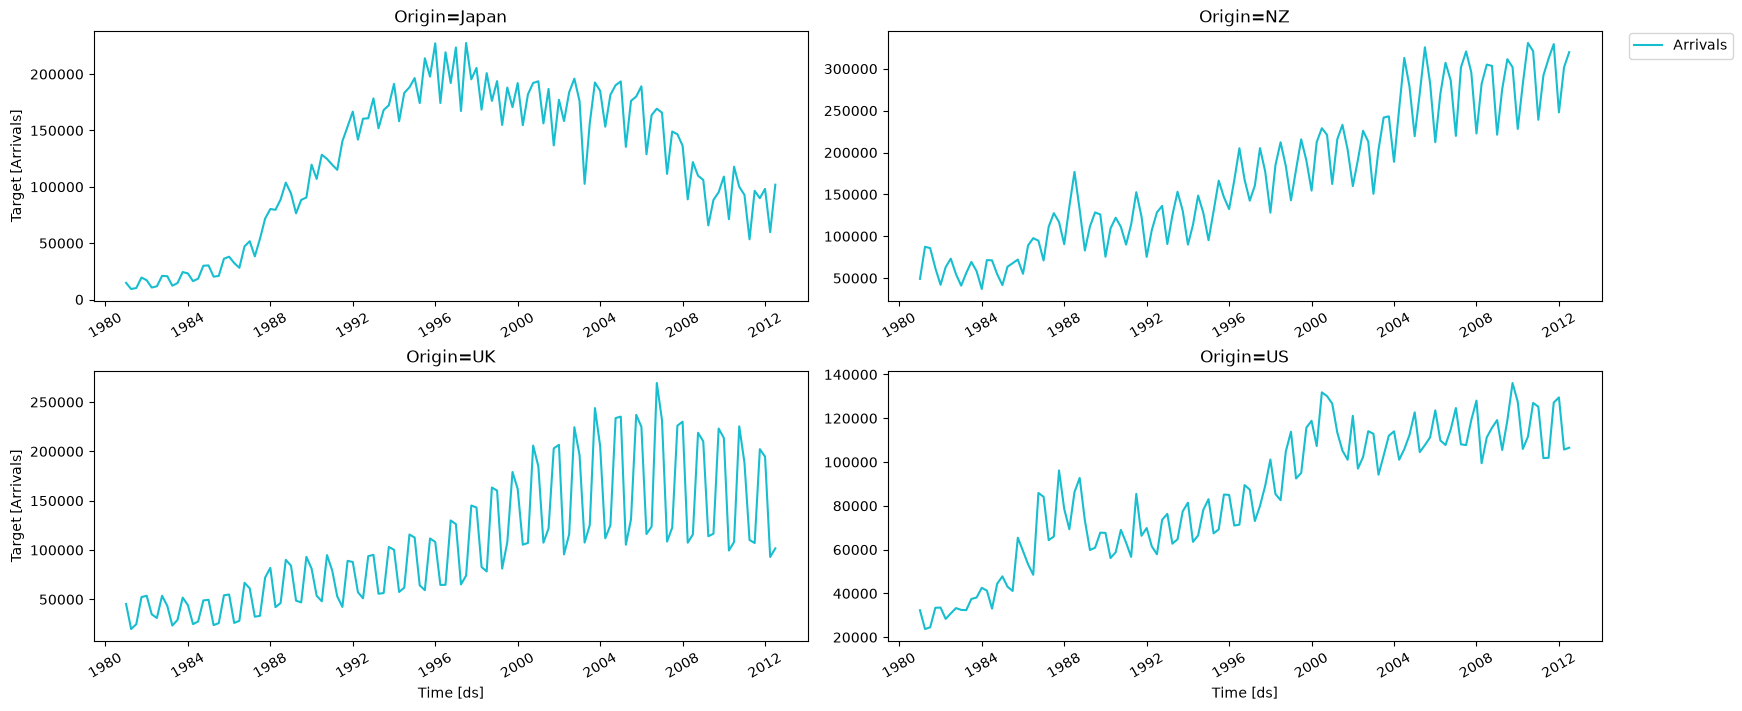

In [27]:
plot_series(aus_arrivals_df, id_col='Origin', target_col='Arrivals')

## Seasonal plots

In [67]:
def seasonal_plot(df:pd.DataFrame, hue_col:str='Year', x_col:str='Month', y_col:str='y', group_col:str="Group"):
    unique_hue_vals = df[hue_col].unique()
    hue_palette = sns.color_palette("husl", n_colors=len(unique_hue_vals))
    for group_name, group_data in df.groupby(group_col):
        fig, ax = plt.subplots()
        sns.lineplot(data=group_data, x=x_col, y=y_col, hue=hue_col, 
                     legend=False, ax=ax, palette=hue_palette)
        ax.set(
            title=f"{y_col} ({group_name})",
            xticks=range(1, 13)
        )
    
        min_hue_val = unique_hue_vals.min()
        for hue_name, subset in group_data.groupby(hue_col):
            x = subset[x_col].iloc[-1] + .1
            y = subset[y_col].iloc[-1]
            color = hue_palette[hue_name - min_hue_val]
            ax.text(x, y, str(hue_name),
                ha="left", va="center", fontsize=7, weight="bold", color=color)
        plt.tight_layout()
        plt.show()

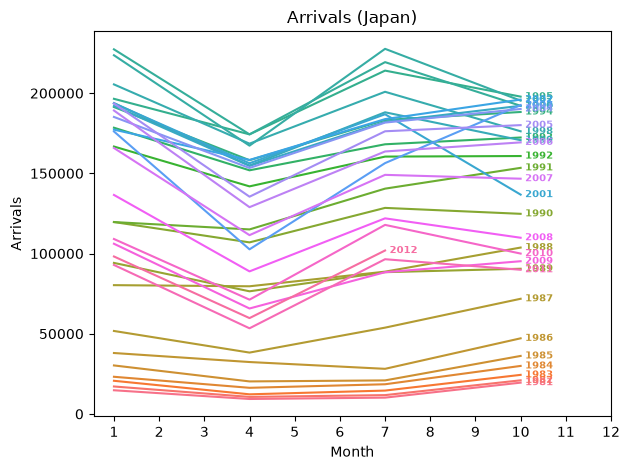

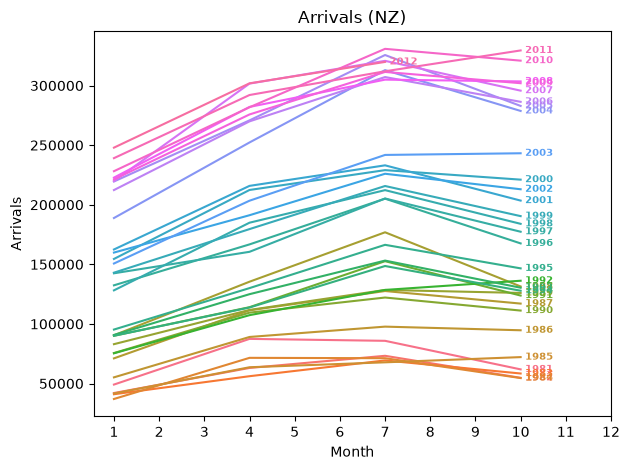

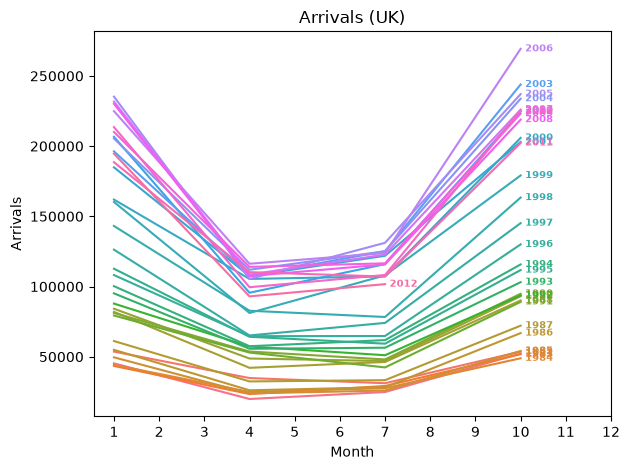

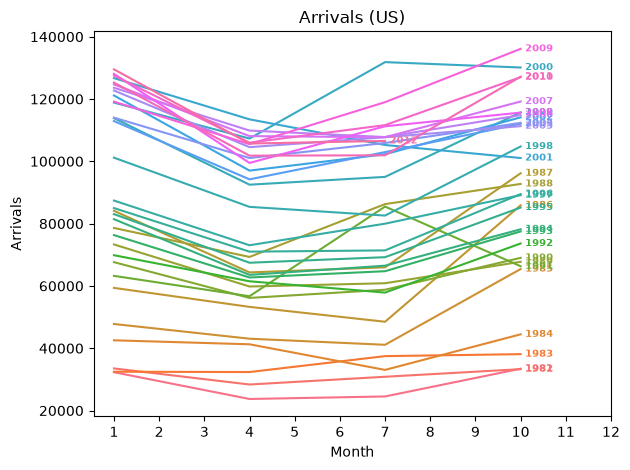

In [68]:
seasonal_plot(aus_arrivals_df, y_col="Arrivals", group_col='Origin')

## Seasonal Subseries plots

In [76]:
def seasonal_subseries(df:pd.DataFrame, group_col:str='Group', y_col:str='y', month_col:str='Month', 
                       month_name_col:str='month_name', year_col:str='Year'):
    for origin, origin_data in df.groupby(group_col):
        n_row_plots = origin_data.groupby([month_col, month_name_col]).ngroups
        fig, axes = plt.subplots(1, n_row_plots, figsize=(12, 4), sharey=True)
        for ax, ((_, month_name), month_df) in zip(
                axes, origin_data.groupby([month_col, month_name_col])):
            mean_y = month_df[y_col].mean()
            ax.plot(month_df[year_col], month_df[y_col], color="k")
            ax.axhline(mean_y, color="b", linewidth=1)
            ax.set(title=month_name[:3], xlabel="")
            ax.tick_params(axis="x", rotation=90)
        
        fig.suptitle(origin)
        fig.supxlabel("Month")
        fig.supylabel(y_col)
        plt.tight_layout()
        plt.show()

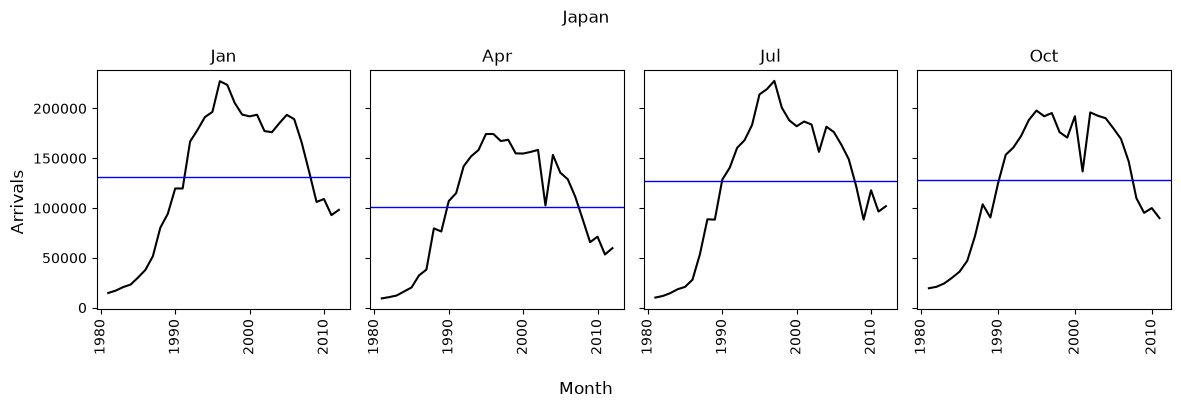

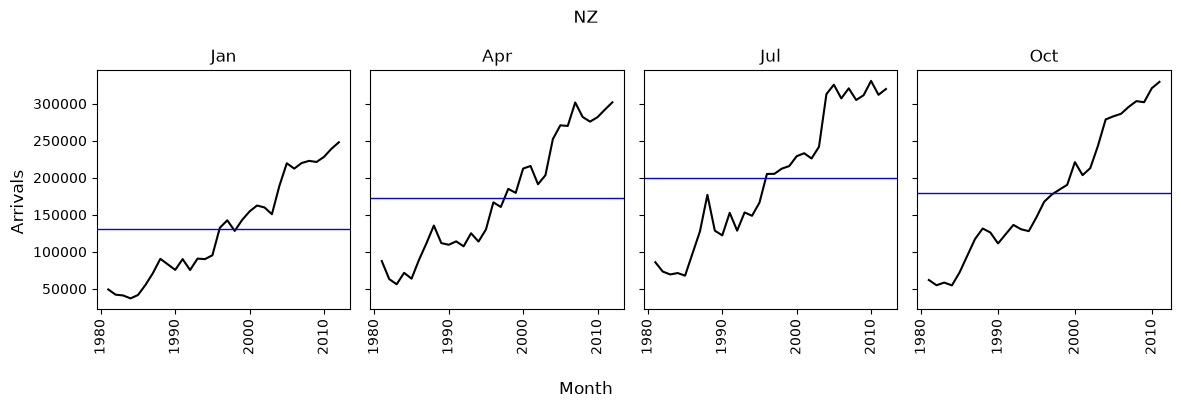

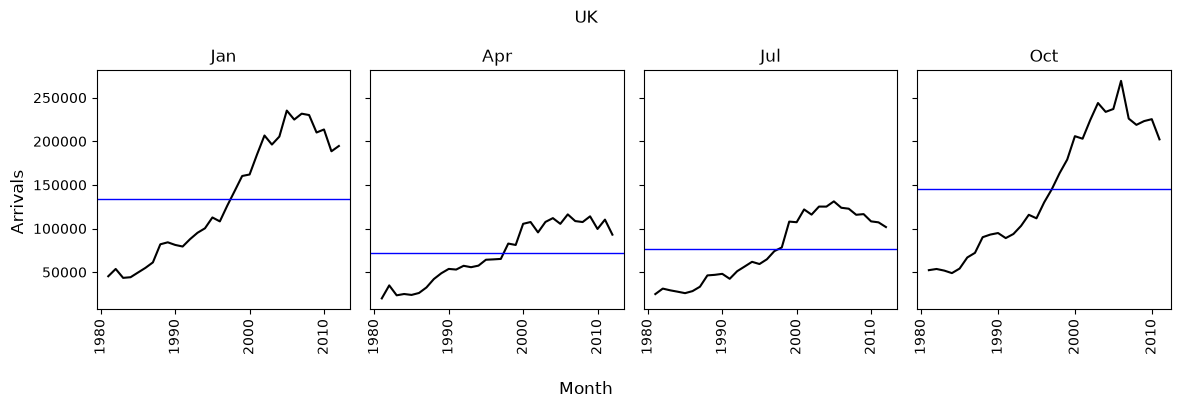

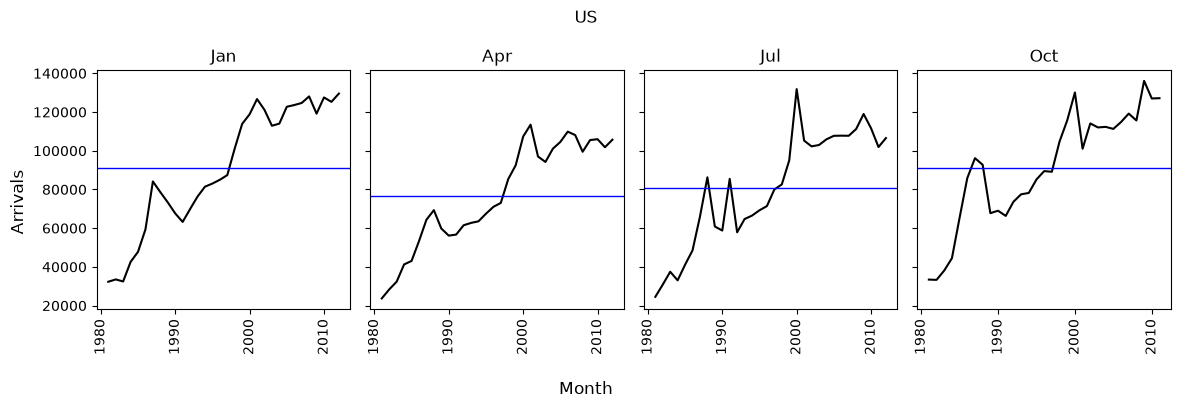

In [78]:
seasonal_subseries(aus_arrivals_df, group_col='Origin', y_col='Arrivals')

# 7

In [59]:
aus_retail_df = pd.read_csv(DATA_DIR + "aus_retail.csv", parse_dates=['Month']).rename(columns={"Month":'ds'})
aus_retail_df = aus_retail_df.assign(Month=aus_retail_df['ds'].dt.month, month_name=aus_retail_df["ds"].dt.month_name(), Year=aus_retail_df["ds"].dt.year)
aus_retail_df.head()

,State,Industry,Series ID,ds,Turnover,Month,month_name,Year
0,Australian Capital Territory,"Cafes, restaurants and catering services",A3349849A,1982-04-01,4.4,4,April,1982
1,Australian Capital Territory,"Cafes, restaurants and catering services",A3349849A,1982-05-01,3.4,5,May,1982
2,Australian Capital Territory,"Cafes, restaurants and catering services",A3349849A,1982-06-01,3.6,6,June,1982
3,Australian Capital Territory,"Cafes, restaurants and catering services",A3349849A,1982-07-01,4.0,7,July,1982
4,Australian Capital Territory,"Cafes, restaurants and catering services",A3349849A,1982-08-01,3.6,8,August,1982


In [60]:
random = np.random.RandomState(55)
random_series_id = random.choice(aus_retail_df["Series ID"].unique())
myseries = aus_retail_df.loc[aus_retail_df["Series ID"] == random_series_id]

In [61]:
myseries

,State,Industry,Series ID,ds,Turnover,Month,month_name,Year
17199,New South Wales,Takeaway food services,A3349792X,1982-04-01,85.4,4,April,1982
17200,New South Wales,Takeaway food services,A3349792X,1982-05-01,84.8,5,May,1982
17201,New South Wales,Takeaway food services,A3349792X,1982-06-01,80.7,6,June,1982
17202,New South Wales,Takeaway food services,A3349792X,1982-07-01,82.4,7,July,1982
17203,New South Wales,Takeaway food services,A3349792X,1982-08-01,80.7,8,August,1982
...,...,...,...,...,...,...,...,...
17635,New South Wales,Takeaway food services,A3349792X,2018-08-01,579.2,8,August,2018
17636,New South Wales,Takeaway food services,A3349792X,2018-09-01,569.2,9,September,2018
17637,New South Wales,Takeaway food services,A3349792X,2018-10-01,588.6,10,October,2018
17638,New South Wales,Takeaway food services,A3349792X,2018-11-01,576.0,11,November,2018


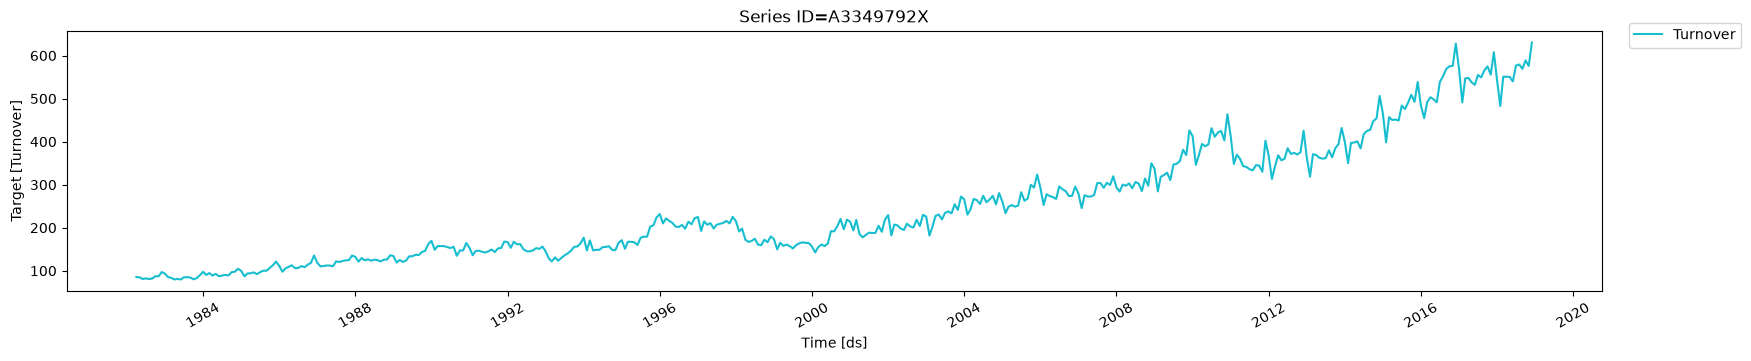

In [58]:
plot_series(myseries, id_col='Series ID', target_col='Turnover')

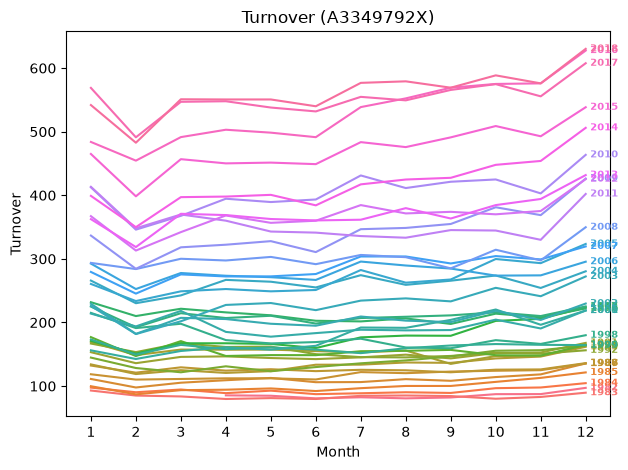

In [69]:
seasonal_plot(myseries, y_col='Turnover', group_col='Series ID')

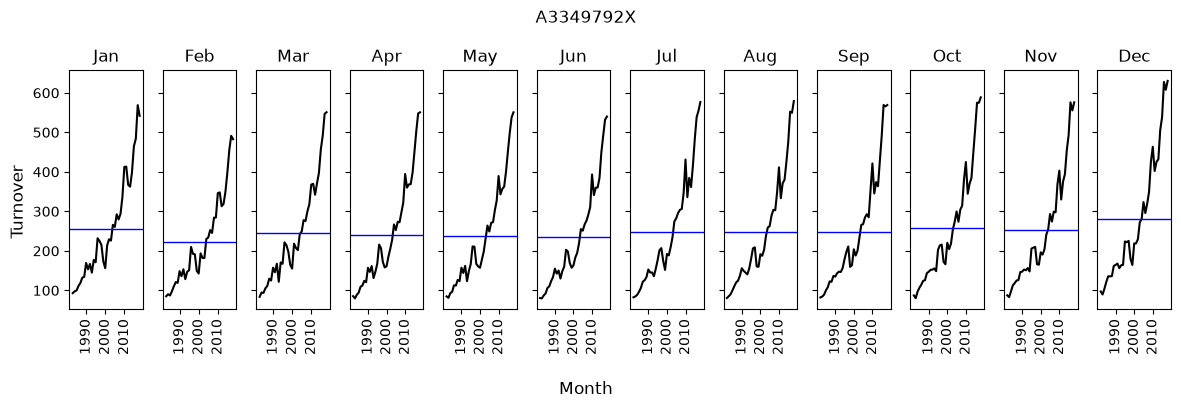

In [79]:
seasonal_subseries(myseries, group_col='Series ID', y_col='Turnover')